# Project 1 Progress Notebook

#### Data: Grocery Store Foods
The foods stocked by grocery stores strongly influence consumer decisions and dietary health. Here, you will examine a dataset of over 50,000 food items sold by Walmart, Target, and Whole Foods that categorizes items based on their degree of processing, price range, and nutritional content.

The data has the following columns:
- `name`: The name of the food product.
- `store`: The store where the product is sold (Walmart, Target, or Whole Foods).
- `category`: The food category of the product.
- `brand`: The brand of the product.
- `FPro`: The Food Processing Score, a value between 0 (minimally processed) to 1 (highly processed), as calculated by the GroceryDB authors using a random forest model.
- `FPro_class`: The predicted NOVA classification for the foodf. 0 = Unprocessed or minimally processed foods; 1 = Processed culinary ingredients; 2 = Processed foods; 3 = Ultra-processed food and drink products.
- `price`: The price of the product.
- `price percal`: The price per calorie.
- `package_weight`: The weight of the package in grams.
- `Protein`: Protein content.
- `Total Fat`: Total fat content.
- `Carbohydrate`: Carbohydrate content.
- `Sugars, total`: Total sugar content.
- `Fiber, total dietary`: Dietary fiber content.
- `Sodium`: Sodium content.
- `Cholesterol`: Cholesterol content.

The nutrition data (protein, fat, carbs, sugar, fiber, sodium, and cholesterol) is normalized to grams per 100g of product.


## Load data

In [87]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 
import matplotlib.ticker as mtick

In [2]:
df = pd.read_csv('grocerydb.csv')
df.shape

(26250, 16)

In [3]:
df.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051


In [4]:
df.dtypes

name                        str
store                       str
category                    str
brand                       str
FPro                    float64
FPro_class              float64
price                   float64
price percal            float64
package_weight          float64
Protein                 float64
Total Fat               float64
Carbohydrate            float64
Sugars, total           float64
Fiber, total dietary    float64
Sodium                  float64
Cholesterol             float64
dtype: object

## Data cleaning

In [5]:
# count missing values 
df.isna().sum()

name                       0
store                      0
category                   0
brand                     69
FPro                       0
FPro_class                 0
price                   4030
price percal            5470
package_weight          1275
Protein                    0
Total Fat                  0
Carbohydrate               0
Sugars, total              9
Fiber, total dietary       9
Sodium                     0
Cholesterol                0
dtype: int64

Lots of missing prices, so analysis and visualizations on price might not be accruate.

## EDA

Look at very basic and simple charts to get an understanding of the data. 

In [6]:
# all unique food categories
df['category'].unique()

<ArrowStringArray>
[              'baby-food',                  'baking',
                   'bread',               'breakfast',
                   'cakes',                  'cereal',
                  'cheese',         'coffee-beans-wf',
         'cookies-biscuit',    'culinary-ingredients',
      'dairy-yogurt-drink',               'dressings',
            'drink-coffee',             'drink-juice',
          'drink-juice-wf',      'drink-shakes-other',
 'drink-soft-energy-mixes',               'drink-tea',
          'drink-water-wf',                 'eggs-wf',
       'ice-cream-dessert',                   'jerky',
              'mac-cheese',           'meat-packaged',
         'meat-poultry-wf',    'milk-milk-substitute',
          'muffins-bagels',           'nuts-seeds-wf',
           'pasta-noodles',  'pastry-chocolate-candy',
                   'pizza',   'prepared-meals-dishes',
        'produce-beans-wf',        'produce-packaged',
           'pudding-jello',    'rice-grains-pa

A few different types of snakcs that can be used for comparison analysis.

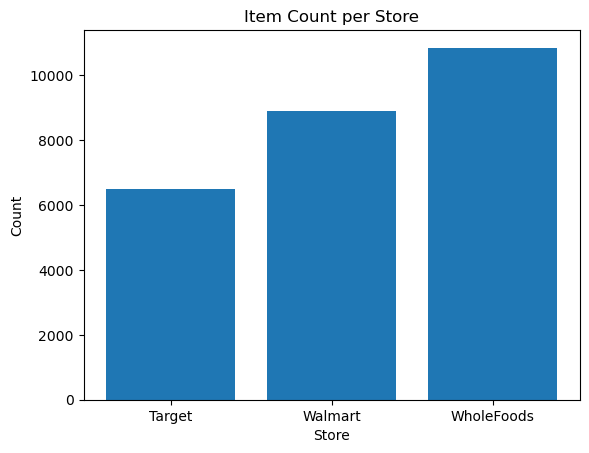

In [7]:
store_count = df.groupby('store').count().reset_index()
plt.bar(store_count['store'], store_count['name'])
plt.xlabel('Store')
plt.ylabel('Count')
plt.title('Item Count per Store')
plt.show()

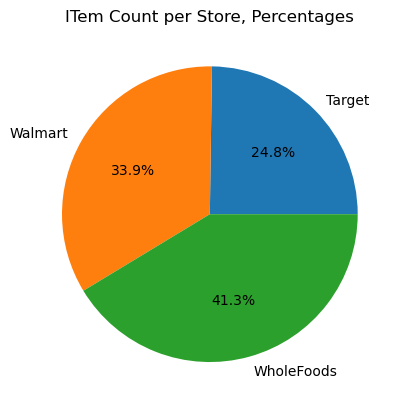

In [8]:
store_perc = store_count['name'] / df.shape[0]
plt.pie(store_perc, labels=store_count['store'], autopct='%1.1f%%')
plt.title('ITem Count per Store, Percentages')
plt.show()

In [ ]:
# FPR null value count
df['Food']

## Better graphs

In [9]:
# average price for each category of food
cat_store_price = df.groupby(by=['category', 'store']).mean(numeric_only=True).reset_index()[['store', 'category', 'price']]
cat_store_price.head()

,store,category,price
0,Target,baby-food,4.170000
1,Walmart,baby-food,2.587273
2,WholeFoods,baby-food,2.350952
3,Target,baking,3.173571
4,Walmart,baking,2.636828


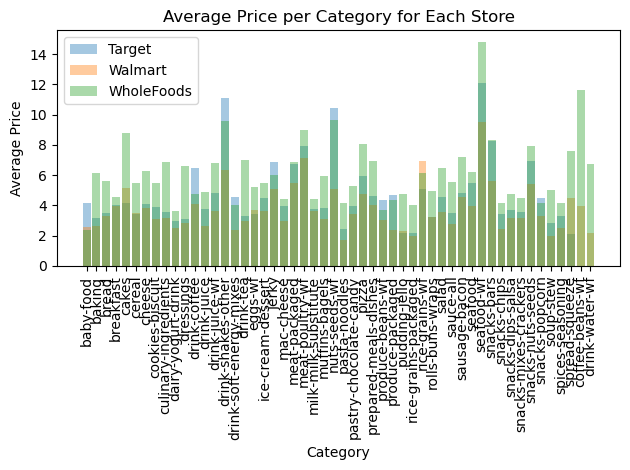

In [10]:
plt.bar(data=cat_store_price[cat_store_price['store']=='Target'], x='category', height='price', label='Target', alpha=0.4)
plt.bar(data=cat_store_price[cat_store_price['store']=='Walmart'], x='category', height='price', label='Walmart', alpha=0.4)
plt.bar(data=cat_store_price[cat_store_price['store']=='WholeFoods'], x='category', height='price', label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Category')
plt.ylabel('Average Price')
plt.xticks(rotation=90)
plt.title('Average Price per Category for Each Store')
plt.tight_layout()
plt.show()

In [11]:
# dataset by store
target = df[df['store']=='Target']
walmart = df[df['store']=='Walmart']
wf = df[df['store']=='WholeFoods']

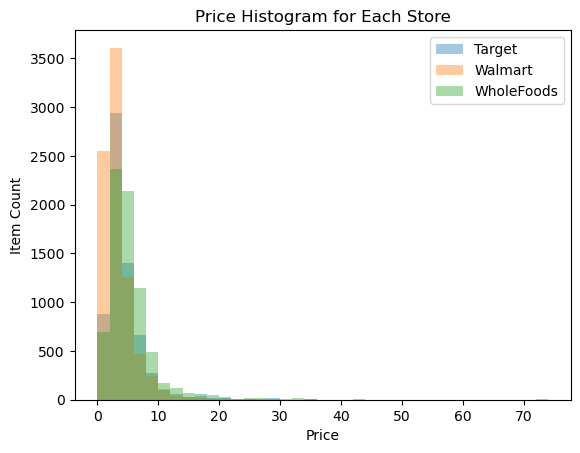

In [12]:
# price histogram, not grouped by category, only by store
bin_width = 2
bin_edges = np.arange(min(df['price']), max(df['price']) + bin_width, bin_width)

plt.hist(x=target['price'], bins=bin_edges, label='Target', alpha=0.4)
plt.hist(x=walmart['price'], bins=bin_edges, label='Walmart', alpha=0.4)
plt.hist(x=wf['price'], bins=bin_edges, label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Price')
plt.ylabel('Item Count')
plt.title('Price Histogram for Each Store')
plt.show()

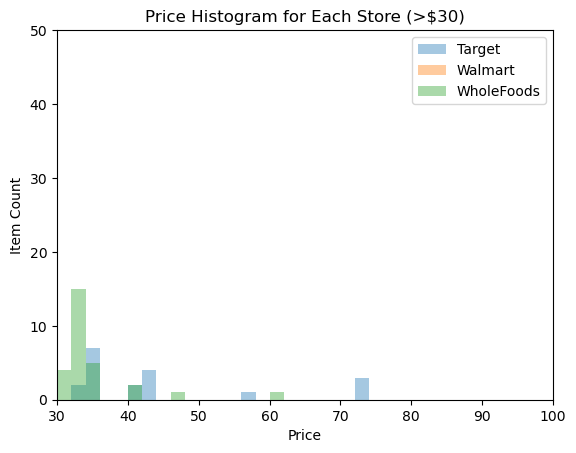

In [13]:
# zoom in on items over 30
plt.hist(x=target['price'], bins=bin_edges, label='Target', alpha=0.4)
plt.hist(x=walmart['price'], bins=bin_edges, label='Walmart', alpha=0.4)
plt.hist(x=wf['price'], bins=bin_edges, label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Price')
plt.ylabel('Item Count')
plt.title('Price Histogram for Each Store (>$30)')
plt.xlim([30, 100])
plt.ylim([0,50])
plt.show()

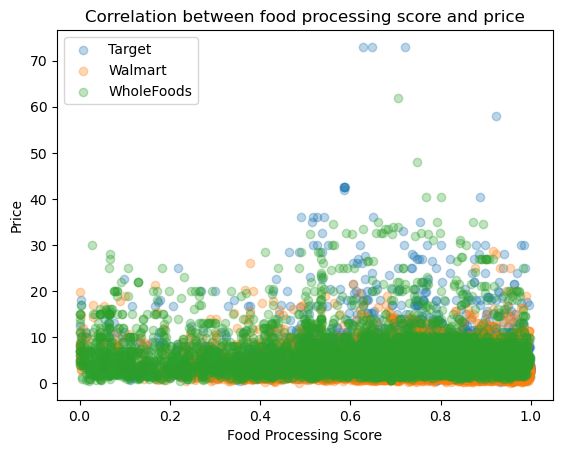

In [14]:
# does food processing score have any correlation with the price?
plt.scatter(target['FPro'], target['price'], alpha=0.3, label='Target')
plt.scatter(walmart['FPro'], walmart['price'], alpha=0.3, label='Walmart')
plt.scatter(wf['FPro'], wf['price'], alpha=0.3, label='WholeFoods')
plt.legend(loc='upper left')
plt.title('Correlation between food processing score and price')
plt.xlabel('Food Processing Score')
plt.ylabel('Price')
plt.show()

In [15]:
target.groupby(['store','FPro_class']).count().reset_index()

,store,FPro_class,name,category,brand,FPro,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Target,0.0,369,369,366,369,369,349,367,369,369,369,369,369,369,369
1,Target,1.0,60,60,60,60,60,57,59,60,60,60,60,60,60,60
2,Target,2.0,585,585,579,585,585,569,585,585,585,585,585,585,585,585
3,Target,3.0,5489,5489,5476,5489,5489,5370,5475,5489,5489,5489,5489,5489,5489,5489


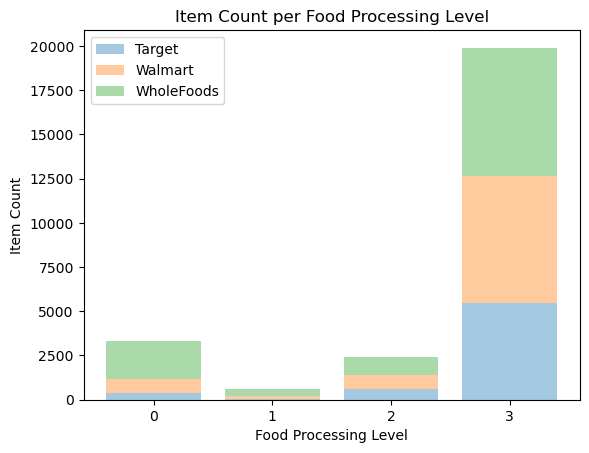

In [ ]:
# does wholefoods really have less processed food?
fpro_class = [0,1,2,3]
target_height = target.groupby('FPro_class').count().reset_index()['name']
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name']
wf_height = wf.groupby('FPro_class').count().reset_index()['name']
plt.bar(fpro_class, target_height, label='Target', alpha=0.4)
plt.bar(fpro_class, walmart_height, label='Walmart', alpha=0.4, bottom=target_height)
plt.bar(fpro_class, wf_height, label='WholeFoods', alpha=0.4, bottom=target_height+walmart_height)
plt.legend()
plt.xticks([0,1,2,3])
plt.xlabel('Food Processing Level')
plt.ylabel('Item Count')
plt.title('Item Count per Food Processing Level')
plt.show()

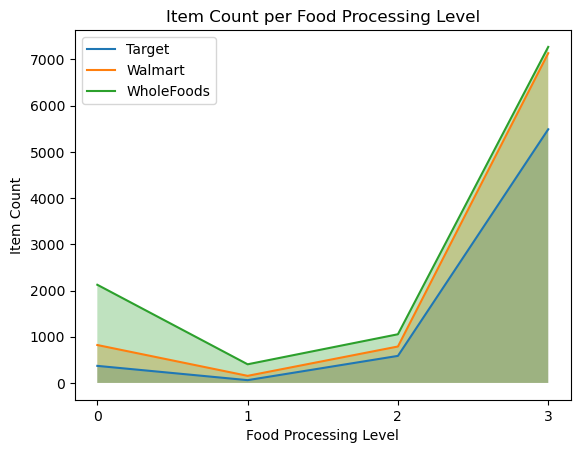

In [ ]:
# does wholefoods really have less processed food?
fpro_class = [0,1,2,3]
target_height = target.groupby('FPro_class').count().reset_index()['name']
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name']
wf_height = wf.groupby('FPro_class').count().reset_index()['name']
plt.plot(fpro_class, target_height, label='Target')
plt.fill_between(fpro_class, target_height, alpha=0.3)
plt.plot(fpro_class, walmart_height, label='Walmart')
plt.fill_between(fpro_class, walmart_height, alpha=0.3)
plt.plot(fpro_class, wf_height, label='WholeFoods')
plt.fill_between(fpro_class, wf_height, alpha=0.3)
plt.legend()
plt.xticks([0,1,2,3])
plt.xlabel('Food Processing Level')
plt.ylabel('Item Count')
plt.title('Item Count per Food Processing Level')
plt.show()

WholeFoods does have more unprocessed food, but it also has more items in general.

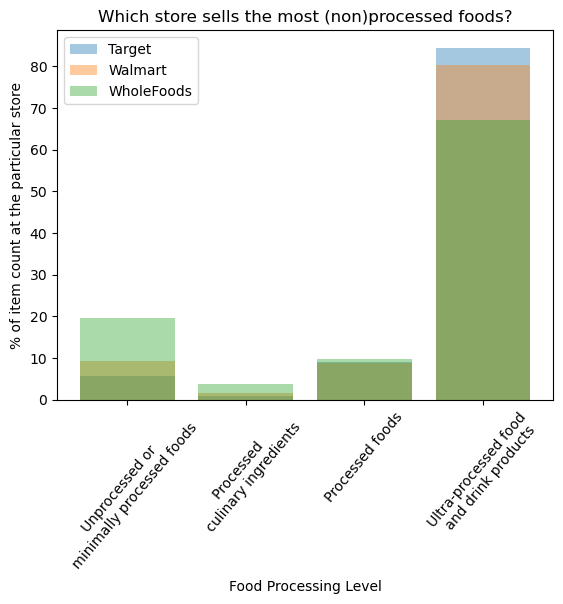

In [66]:
# percentage of processed food at the store
fpro_class = [0,1,2,3]
target_height = target.groupby('FPro_class').count().reset_index()['name'] / target.shape[0] *100
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name'] / walmart.shape[0] *100
wf_height = wf.groupby('FPro_class').count().reset_index()['name'] / wf.shape[0] *100
plt.bar(fpro_class, target_height, label='Target', alpha=0.4)
plt.bar(fpro_class, walmart_height, label='Walmart', alpha=0.4)
plt.bar(fpro_class, wf_height, label='WholeFoods', alpha=0.4)
plt.legend()
plt.xticks(fpro_class, ['Unprocessed or \n minimally processed foods', 'Processed \n culinary ingredients', 'Processed foods', 'Ultra-processed food\n and drink products'], rotation=50)
plt.xlabel('Food Processing Level')
plt.ylabel('% of item count at the particular store')
plt.title('Which store sells the most (non)processed foods?')
plt.show()

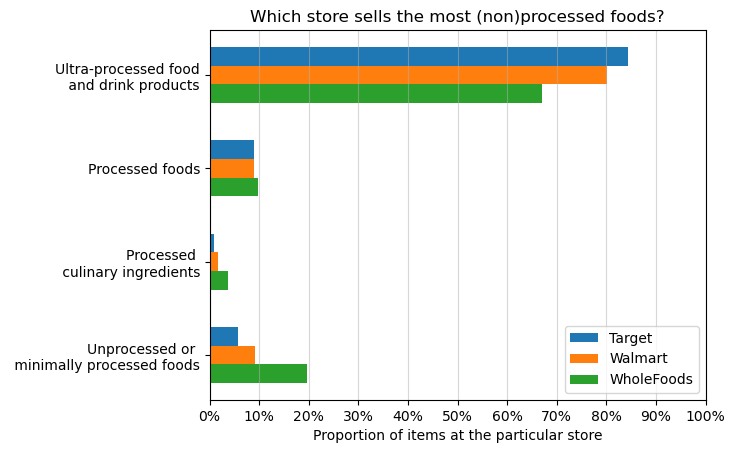

In [100]:
# percentage of processed food at the store -> horizontal bars
fpro_class = [0,1,2,3]
fpro_class_labels = ['Unprocessed or \n minimally processed foods', 'Processed \n culinary ingredients', 'Processed foods', 'Ultra-processed food\n and drink products']
target_height = target.groupby('FPro_class').count().reset_index()['name'] / target.shape[0] *100
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name'] / walmart.shape[0] *100
wf_height = wf.groupby('FPro_class').count().reset_index()['name'] / wf.shape[0] *100

# plt.grouped_bar(
#     [target_height, walmart_height, wf_height], 
#     tick_labels=fpro_class_labels, 
#     labels=['Target', 'Walmart', 'WholeFoods']
# )
x = np.arange(len(fpro_class_labels))
w = 0.2

plt.barh(x+w, target_height, height=w, label='Target')
plt.barh(x, walmart_height, height=w, label='Walmart')
plt.barh(x-w, wf_height, height=w, label='WholeFoods')
plt.legend()
plt.yticks(fpro_class, fpro_class_labels)
plt.grid(axis='x', alpha=0.5)
# plt.ylabel('Food Processing Class')
plt.xlim([0,100])
plt.xticks(range(0,101,10))
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter())
plt.xlabel('Proportion of items at the particular store')
plt.title('Which store sells the most (non)processed foods?')
plt.show()

In [75]:
import matplotlib

# Correct way to access the version
print(matplotlib.__version__)

3.10.8


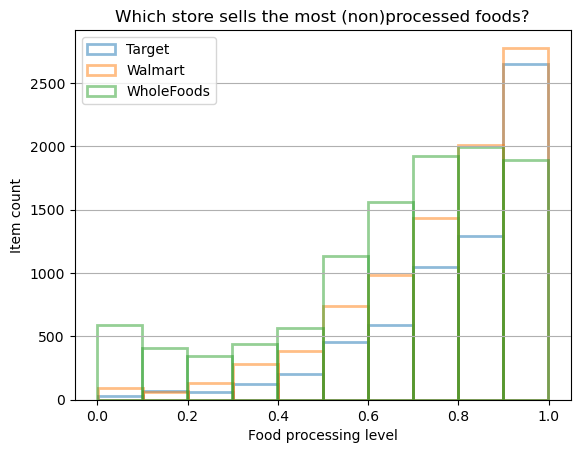

In [60]:
# percentage of processed food at the store -> FPRo [0,1], not class label

# plt.hist(target['FPro'], label='Target', alpha=0.4, ec='None')
# plt.hist(walmart['FPro'], label='Walmart', alpha=0.4, ec='None')
# plt.hist(wf['FPro'], label='WholeFoods', alpha=0.4, ec='None')

plt.hist(target['FPro'], label='Target', fc='None', ec='tab:blue', lw=2, alpha=0.5)
plt.hist(walmart['FPro'], label='Walmart', fc='None', ec='tab:orange', lw=2, alpha=0.5)
plt.hist(wf['FPro'], label='WholeFoods', fc='None', ec='tab:green', lw=2, alpha=0.5)


plt.legend()
plt.xlabel('Food processing level')
plt.ylabel('Item count')
plt.title('Which store sells the most (non)processed foods?')
plt.grid(axis='y')
plt.show()

In [19]:
# what brand has the highest price (on average)?
brands = df.groupby('brand').mean(numeric_only=True).reset_index()
brands.sort_values('price', ascending=False)

,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
2944,TB12 Sports,0.748722,3.0,47.990000,0.013435,952.543977,75.000000,6.250000,9.375000,0.000000,3.125000,1.093750,0.000000
910,Evo Hemp,0.602944,2.4,34.490000,0.012098,156.489240,19.919430,25.729264,40.253848,10.374703,10.374703,0.123666,0.000000
2217,One Brand,0.771889,3.0,32.280000,0.016276,540.908460,26.666667,15.555556,46.666667,2.222222,17.777778,0.355556,0.000000
2218,One Brands,0.692889,3.0,32.280000,0.016784,540.908460,26.666667,15.555556,46.666667,2.222222,20.000000,0.422222,0.000000
2457,READYWISE,0.763571,3.0,31.656667,0.009991,907.184740,3.115265,1.557632,83.136033,62.242991,14.226376,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3382,di stefano,0.582704,2.0,NaN,NaN,226.796000,14.109596,14.109596,3.527399,3.527399,0.000000,0.176370,0.052911
3387,gimMe,0.523222,3.0,NaN,NaN,22.963095,38.461538,0.000000,38.461538,0.000000,38.461538,0.192308,0.000000
3392,joyböl,0.880389,3.0,NaN,NaN,59.533950,19.166667,15.000000,58.333333,12.500000,7.500000,0.300000,0.000000
3393,kitchfix,0.691826,3.0,NaN,NaN,255.145500,2.352941,8.235294,31.176471,0.588235,1.764706,0.188235,0.041176


In [20]:
# does the same brand sell at different prices in different stores?

# filter for brands that are sold at all three stores
# some rows have null price
store_brands = df.dropna(subset=['price']).groupby(['store', 'brand']).mean(numeric_only=True).reset_index()
brands_store_count = store_brands.groupby('brand').count()
brands_all3 = brands_store_count[brands_store_count['store']==3].reset_index()['brand']
brands_all3

0              Banza
1         Bear Naked
2      Birch Benders
3            Biscoff
4     Bob's Red Mill
           ...      
60           Walkers
61              Wasa
62       Wild Planet
63          YumEarth
64           siggi's
Name: brand, Length: 65, dtype: str

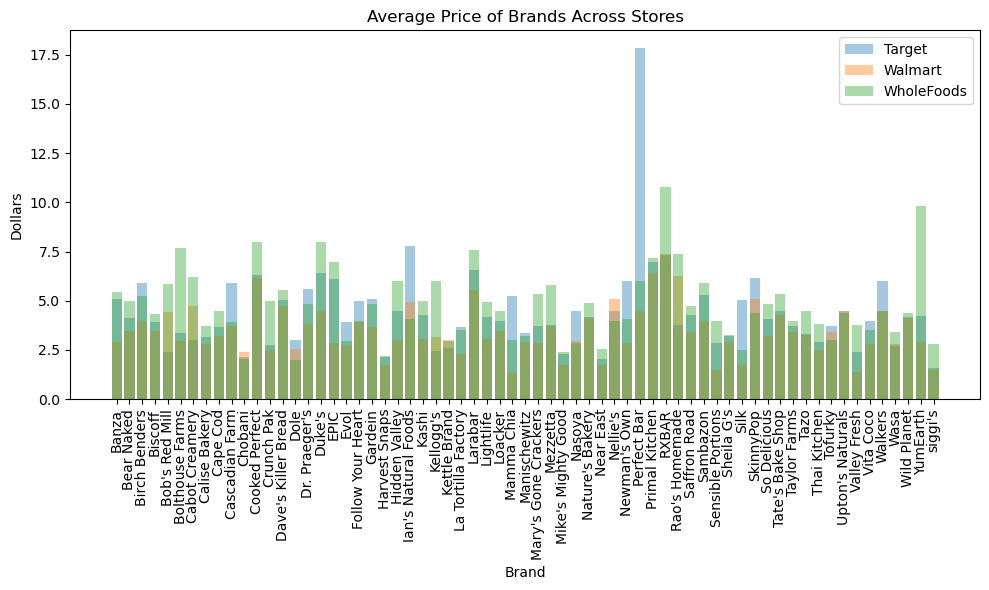

In [21]:
brand_all3_meanprice = df[df['brand'].isin(brands_all3)].groupby(['store', 'brand']).mean(numeric_only=True).reset_index()[['store', 'brand', 'price']]
target_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='Target']
walmart_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='Walmart']
wf_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='WholeFoods']

plt.figure(figsize=(10,6))
plt.bar(target_brand_mp['brand'], target_brand_mp['price'], alpha=0.4, label='Target')
plt.bar(walmart_brand_mp['brand'], walmart_brand_mp['price'], alpha=0.4, label='Walmart')
plt.bar(wf_brand_mp['brand'], wf_brand_mp['price'], alpha=0.4, label='WholeFoods')
plt.legend()
plt.xlabel('Brand')
plt.ylabel('Dollars')
plt.title('Average Price of Brands Across Stores')
# plt.xticks([])   #empty ticks to declutter
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [22]:
# visualizaiton is unclear so we're counting numberically 
idx = brand_all3_meanprice.groupby('brand')['price'].idxmax()
brand_all3_meanprice.loc[idx].value_counts('store')

store
WholeFoods    42
Target        20
Walmart        3
Name: count, dtype: int64

In [23]:
# group by wholefood max -> target max -> walmart max to compare the numeric count easier

In [24]:
# how much more expensive are items sold in wholefoods?
tw_brand_mp = pd.concat([target_brand_mp, walmart_brand_mp]).groupby('brand').mean(numeric_only=True)
# tw_brand_meanprice = target_brand_mp.join(walmart_brand_mp, how='inner', on='brand').groupby('brand').mean(numeric_only=True)
versus_joined = wf_brand_mp.join(tw_brand_mp, on='brand', lsuffix='_wf', rsuffix='_tw_avg')
wf_perc_diff = versus_joined['price_wf'] / versus_joined['price_tw_avg'] -1

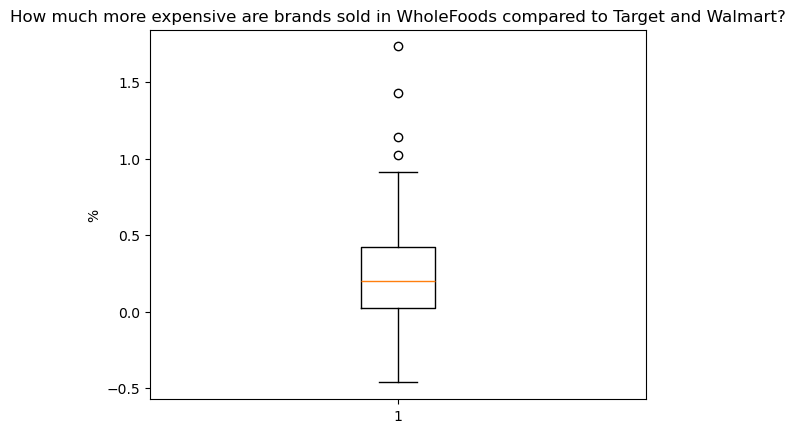

In [25]:
plt.boxplot(wf_perc_diff)
plt.title('How much more expensive are brands sold in WholeFoods compared to Target and Walmart?')
plt.ylabel('%')
plt.show()

In [26]:
target_brand_mp

,store,brand,price
0,Target,Banza,5.075714
1,Target,Bear Naked,4.115000
2,Target,Birch Benders,5.906667
3,Target,Biscoff,3.923333
4,Target,Bob's Red Mill,2.390000
...,...,...,...
60,Target,Walkers,5.990000
61,Target,Wasa,2.690000
62,Target,Wild Planet,4.190000
63,Target,YumEarth,4.240000


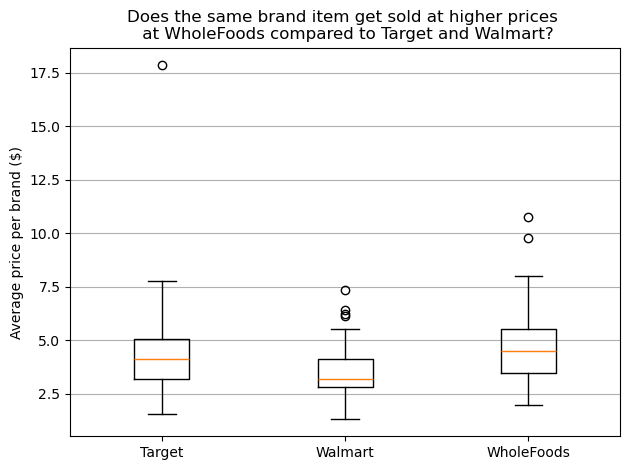

In [27]:
plt.boxplot([target_brand_mp['price'], walmart_brand_mp['price'], wf_brand_mp['price']])
plt.xticks(ticks=[1,2,3], labels=['Target', 'Walmart', 'WholeFoods'])
# plt.xlabel('Brand')
plt.ylabel('Average price per brand ($)')
plt.grid(axis='y')
plt.title('Does the same brand item get sold at higher prices \n at WholeFoods compared to Target and Walmart?')
# plt.subtitle('Average price per brand at different grocery stores')
plt.tight_layout()
plt.show()

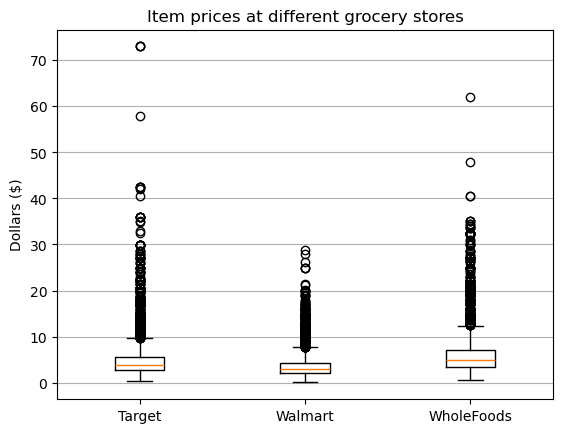

In [28]:
# overall average price regardless of brand
plt.boxplot([target['price'].dropna(), walmart['price'].dropna(), wf['price'].dropna()])
plt.xticks(ticks=[1,2,3], labels=['Target', 'Walmart', 'WholeFoods'])
# plt.xlabel('Brand')
plt.ylabel('Dollars ($)')
plt.grid(axis='y')
plt.title('Item prices at different grocery stores')
plt.show()

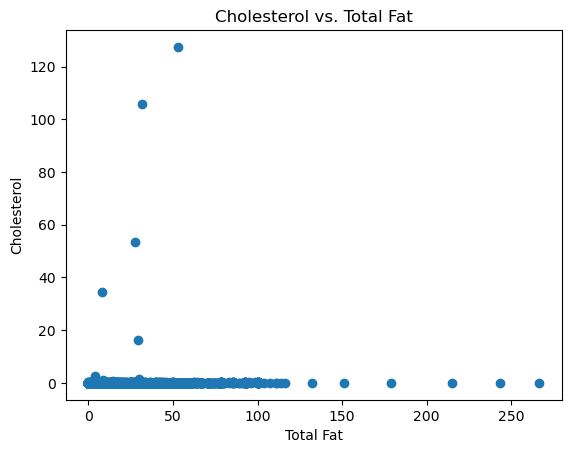

In [29]:
# correlation between fat and cholesterol
plt.scatter(df['Total Fat'], df['Cholesterol'])
plt.xlabel('Total Fat')
plt.ylabel('Cholesterol')
plt.title('Cholesterol vs. Total Fat')
plt.show()

In [30]:
# nutrition between different snack categories
is_snack = df[df['category'].str.contains('snack')]
snack_cat = is_snack.groupby('category').mean(numeric_only=True)
snack_cat

,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
category,,,,,,,,,,,,
snacks-bars,0.802740,2.822397,7.764474,0.009723,269.596229,16.242717,18.523540,51.709138,22.557986,8.678395,0.481686,0.004955
snacks-chips,0.881418,2.949898,3.386820,0.005512,206.490119,8.913645,27.303850,57.907110,4.187794,5.027450,0.643640,0.004384
snacks-dips-salsa,0.757874,2.902870,3.927288,0.014846,335.655866,4.109383,11.767036,13.735908,4.347724,2.843271,0.654074,0.008322
snacks-mixes-crackers,0.880533,2.923835,3.634414,0.005858,280.563932,9.584123,16.541370,63.923872,10.441529,4.110957,0.702245,0.007145
snacks-nuts-seeds,0.606865,2.154062,6.647258,0.005637,330.763690,16.623465,40.055319,33.787450,13.840529,7.557058,0.349343,0.004101
snacks-popcorn,0.861224,2.908654,3.844521,0.005081,312.929563,8.069971,24.573159,57.459231,7.079351,9.747714,0.648949,0.003569


In [31]:
snack_cat_names = snack_cat.index.str.removeprefix('snacks-')
nutrition_cols = ['Protein', 'Total Fat', 'Carbohydrate', 'Sugars, total', 'Fiber, total dietary', 'Sodium', 'Cholesterol']
snacks_nutrition = snack_cat[nutrition_cols].set_index(snack_cat_names)
snacks_nutrition

,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
category,,,,,,,
bars,16.242717,18.523540,51.709138,22.557986,8.678395,0.481686,0.004955
chips,8.913645,27.303850,57.907110,4.187794,5.027450,0.643640,0.004384
dips-salsa,4.109383,11.767036,13.735908,4.347724,2.843271,0.654074,0.008322
mixes-crackers,9.584123,16.541370,63.923872,10.441529,4.110957,0.702245,0.007145
nuts-seeds,16.623465,40.055319,33.787450,13.840529,7.557058,0.349343,0.004101
popcorn,8.069971,24.573159,57.459231,7.079351,9.747714,0.648949,0.003569


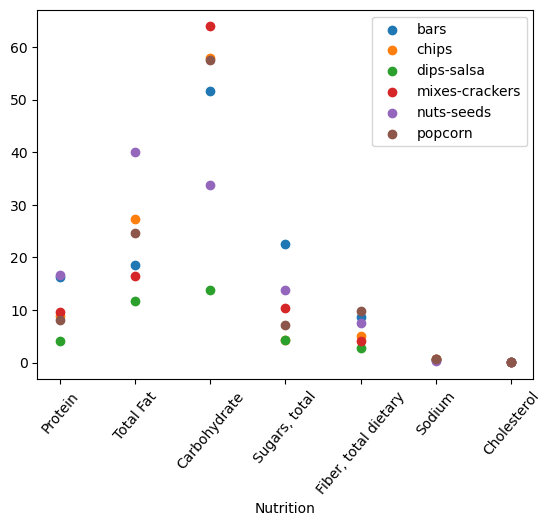

In [32]:
for i in snack_cat_names:
    plt.scatter(nutrition_cols, snacks_nutrition.loc[i], label=i)
    # plt.fill_between(nutrition_cols, snacks_nutrition.loc[i], alpha=0.3)
plt.xlabel('Nutrition')
plt.ylabel('')   #all different units?
plt.legend()
plt.xticks(rotation=50)
plt.show()

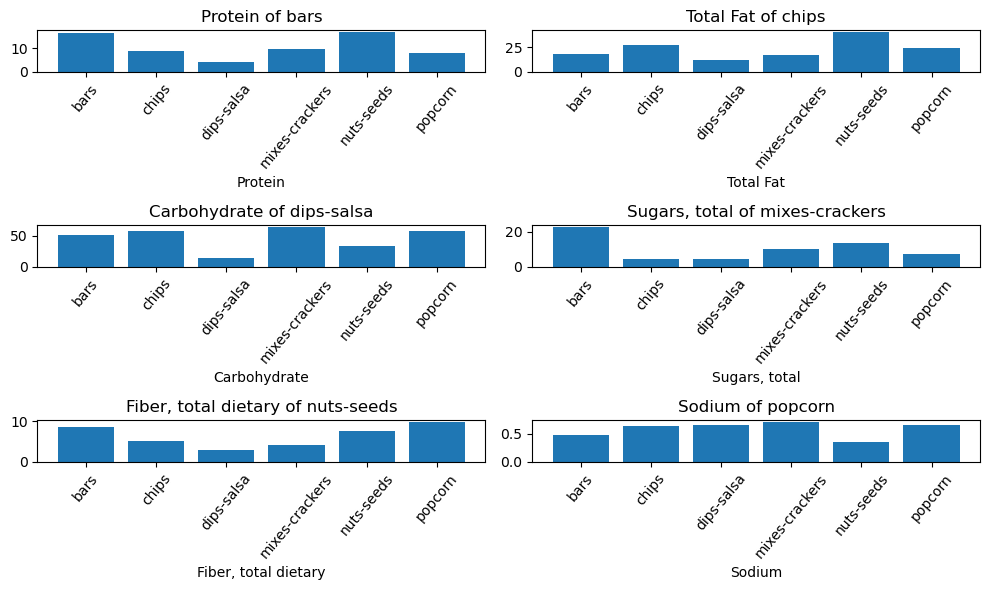

In [33]:
# bars = df[df['category']=='snacks-bars']
# chips = df[df['category']=='snacks-chips']
# dips_salsa = df[df['category']=='snacks-dips-salsa']
# mixes_crackers = df[df['category']=='snacks-mixes-crackers']
# nuts_seeds = df[df['category']=='snacks-nuts-seeds']
# popcorn = df[df['category']=='snacks-popcorn']

# create subplot
fig, axes = plt.subplots(3, 2, figsize=(10, 6))
axes_flat = axes.flatten()

for i, ax in enumerate(axes_flat):
  ax.bar(snack_cat_names, snacks_nutrition.iloc[:,i])
  ax.set_title(f'{nutrition_cols[i]} of {snack_cat_names[i]}')
  ax.set_xlabel(f'{nutrition_cols[i]}')
  ax.tick_params(axis='x', rotation=50)
  
# Adjust spacing so labels don't overlap
plt.tight_layout()
plt.show()